# Tarea 1. Fundamentos de Simulación y Modelación Probabilística

# Objetivo
Comparar un modelo determinístico y uno estocástico de una misma situación, utilizando los mismo parametros iniciales y consecuentemente presentarse mediante una grafica comparativa. Además generar,
describir y visualizar 1,000 observaciones de las distribuciones uniforme, normal,
exponencial y Poisson. Seguidamente contrastar las medias y varianzas simuladas con sus valores teóricos para evaluar el comportamiento de las variables simuladas.

In [13]:
import sys
import math
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
SEMILLA = 42
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,})
pd.options.display.float_format = "{:,.5f}".format

# Actividad 1.  Comparación de modelos

# Situación y supuestos
Se representara el monto diario de ventasen pesos de un objeto durante 30 días. El monto inicial es de $1,000 y la tasa de crecimiento de
referencia es de 2 % diario.

Los dos modelos comparten monto inicial, tasa de referencia y horizonte. El modelo
estocástico añade una perturbación diaria independiente, uniforme entre −0.08 y 0.08.

In [15]:
# Parámetros.
venta_inicial = 1000.0
tasa = 0.02
dias = 30
tiempo = np.arange(dias + 1)

# Modelo determinístico
deterministico = venta_inicial * (1 + tasa) ** tiempo

# Modelo estocástico:
rng_modelo = np.random.default_rng(SEMILLA)
amplitud = 0.08
errores = rng_modelo.uniform(-amplitud, amplitud, size=dias)
estocastico = np.empty(dias + 1)
estocastico[0] = venta_inicial
for t in range(1, dias + 1):
    estocastico[t] = estocastico[t - 1] * (1 + tasa + errores[t - 1])

resultados_modelos = pd.DataFrame({
    "Día": tiempo,
    "Ventas determinísticas": deterministico,
    "Ventas estocásticas ": estocastico,
})
display(resultados_modelos.round(2))

,Día,Ventas determinísticas,Ventas estocásticas
0,0,"1,000.00000","1,000.00000"
1,1,"1,020.00000","1,063.83000"
2,2,"1,040.40000","1,074.71000"
3,3,"1,061.21000","1,157.86000"
4,4,"1,082.43000","1,217.58000"
5,5,"1,104.08000","1,162.88000"
6,6,"1,126.16000","1,274.63000"
7,7,"1,148.69000","1,353.38000"
8,8,"1,171.66000","1,442.39000"
9,9,"1,195.09000","1,385.41000"


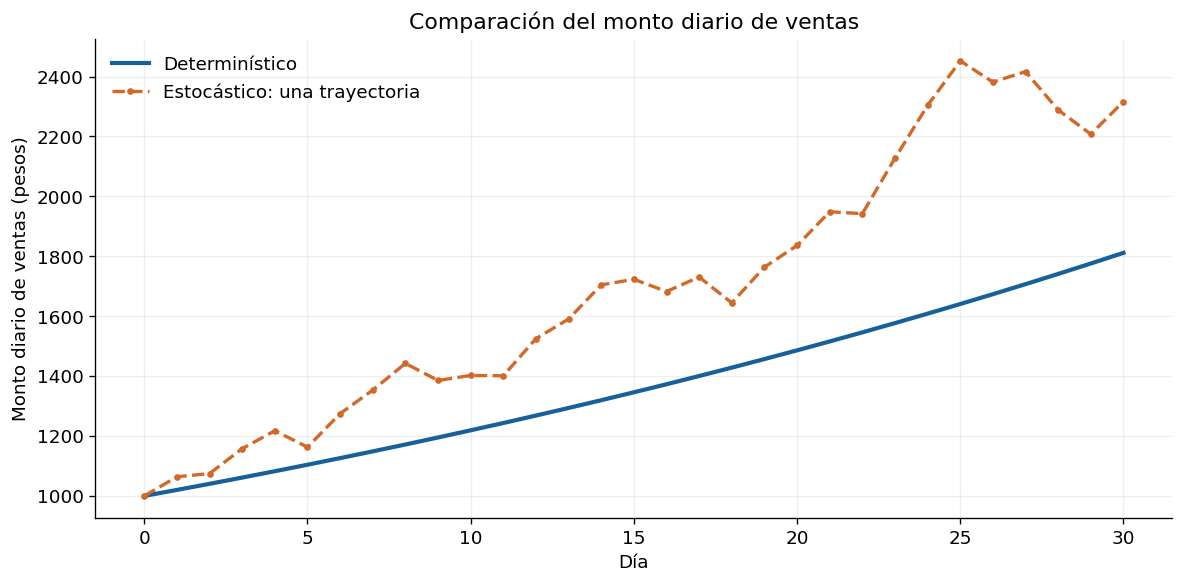

Día 30 — determinístico: $1,811.36
Día 30 — estocástico:    $2,316.46


In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tiempo, deterministico, color="#17619A", linewidth=2.5, label="Determinístico")
ax.plot(tiempo, estocastico, color="#D16A29", linewidth=2, linestyle="--", marker="o", markersize=3, label="Estocástico: una trayectoria")
ax.set(title="Comparación del monto diario de ventas", xlabel="Día", ylabel="Monto diario de ventas (pesos)")
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print(f"Día 30 — determinístico: ${deterministico[-1]:,.2f}")
print(f"Día 30 — estocástico:    ${estocastico[-1]:,.2f}")

Ambos modelos parten de mil pesos y comparten una tasa de crecimiento de referencia del dos por ciento diario.

El modelo determinístico produce una trayectoria suave y fija sin altibajos, determinada por esos parámetros.

En cambio, el modelo estocástico introduce perturbaciones independientes en la tasa diaria, por lo que presenta fluctuaciones y pueden observarse descensos aun cuando el crecimiento de referencia sea positivo.

 Las diferencias entre las curvas muestran el efecto de la incertidumbre. Otra semilla produciría una trayectoria estocástica distinta por la simulacion de los datos, mientras que la curva determinística permanecería igual.

 Esto nos hace comprender que al incorporar aleatoriedad nos permite explorar escenarios de demanda variable y reconocer que una única trayectoria no describe todos los resultados posibles.

# Actividad 2. Generación de números y variables aleatorias
Se generan 1,000 observaciones por distribución, utilizando el generador con semilla 42. Estaran organizadas en el orden uniforme, normal,
exponencial y Poisson.

| Distribución | Parámetros | Media teórica | Varianza teórica |
|---|---|---:|---:|
| Uniforme | $U(0,1)$ | $1/2$ | $1/12$ |
| Normal | $N(0,1)$: media 0, varianza 1 | 0 | 1 |
| Exponencial | Tasa $\lambda=1$ | $1/\lambda=1$ | $1/\lambda^2=1$ |
| Poisson | $\lambda=5$ | 5 | 5 |

Se calcula la varianza muestral con divisor \(n-1\) (ddof=1).

In [18]:
n = 1000
rng = np.random.default_rng(SEMILLA)
# números pseudoaleatorios uniformes.
uniforme = rng.uniform(low=0, high=1, size=n)
# variables de las tres distribuciones indicadas.
normal = rng.normal(loc=0, scale=1, size=n)
lambda_exp = 1.0
exponencial = rng.exponential(scale=1 / lambda_exp, size=n)
poisson = rng.poisson(lam=5, size=n)
datos = pd.DataFrame({"Uniforme": uniforme, "Normal": normal,"Exponencial": exponencial, "Poisson": poisson,})
print(f"Datos generados: {datos.shape[0]} filas y {datos.shape[1]} distribuciones.")
display(datos.head(11))

Datos generados: 1000 filas y 4 distribuciones.


,Uniforme,Normal,Exponencial,Poisson
0,0.77396,-0.74219,0.52204,6
1,0.43888,0.92436,0.58617,5
2,0.85860,0.03461,0.23167,5
3,0.69737,-0.28280,0.38252,9
4,0.09418,-0.10618,0.20184,5
5,0.97562,0.22312,0.27869,8
6,0.76114,0.61681,1.19769,3
7,0.78606,-0.99971,0.53477,8
8,0.12811,-1.04159,1.36552,7
9,0.45039,1.10468,0.27655,4


# Estadísticos descriptivos

In [19]:
descriptivos = pd.DataFrame({
    "n": datos.count(),
    "Media": datos.mean(),
    "Varianza": datos.var(ddof=1),
    "Desviación estándar": datos.std(ddof=1),
    "Mínimo": datos.min(),
    "Máximo": datos.max(),})
descriptivos.index.name = "Distribución"
display(descriptivos)

,n,Media,Varianza,Desviación estándar,Mínimo,Máximo
Distribución,,,,,,
Uniforme,1000,0.49718,0.08502,0.29159,0.00123,0.99910
Normal,1000,-0.07788,1.02916,1.01447,-3.04763,2.91424
Exponencial,1000,0.98623,0.96590,0.98280,0.00019,9.51812
Poisson,1000,4.91400,5.26387,2.29431,0.00000,14.00000


# Comparación entre estadísticos simulados y teóricos

In [21]:
comparacion = pd.DataFrame({
    "Media teórica": [0.5, 0.0, 1.0, 5.0],
    "Media simulada": descriptivos["Media"],
    "Varianza teórica": [1 / 12, 1.0, 1.0, 5.0],
    "Varianza simulada": descriptivos["Varianza"],},
                           index=datos.columns)
comparacion.index.name = "Distribución"
comparacion["Error absoluto media"] = abs(
    comparacion["Media simulada"] - comparacion["Media teórica"])
comparacion["Error absoluto varianza"] = abs(
    comparacion["Varianza simulada"] - comparacion["Varianza teórica"])
display(comparacion)


,Media teórica,Media simulada,Varianza teórica,Varianza simulada,Error absoluto media,Error absoluto varianza
Distribución,,,,,,
Uniforme,0.50000,0.49718,0.08333,0.08502,0.00282,0.00169
Normal,0.00000,-0.07788,1.00000,1.02916,0.07788,0.02916
Exponencial,1.00000,0.98623,1.00000,0.96590,0.01377,0.03410
Poisson,5.00000,4.91400,5.00000,5.26387,0.08600,0.26387


# Histogramas y gráfico de frecuencias

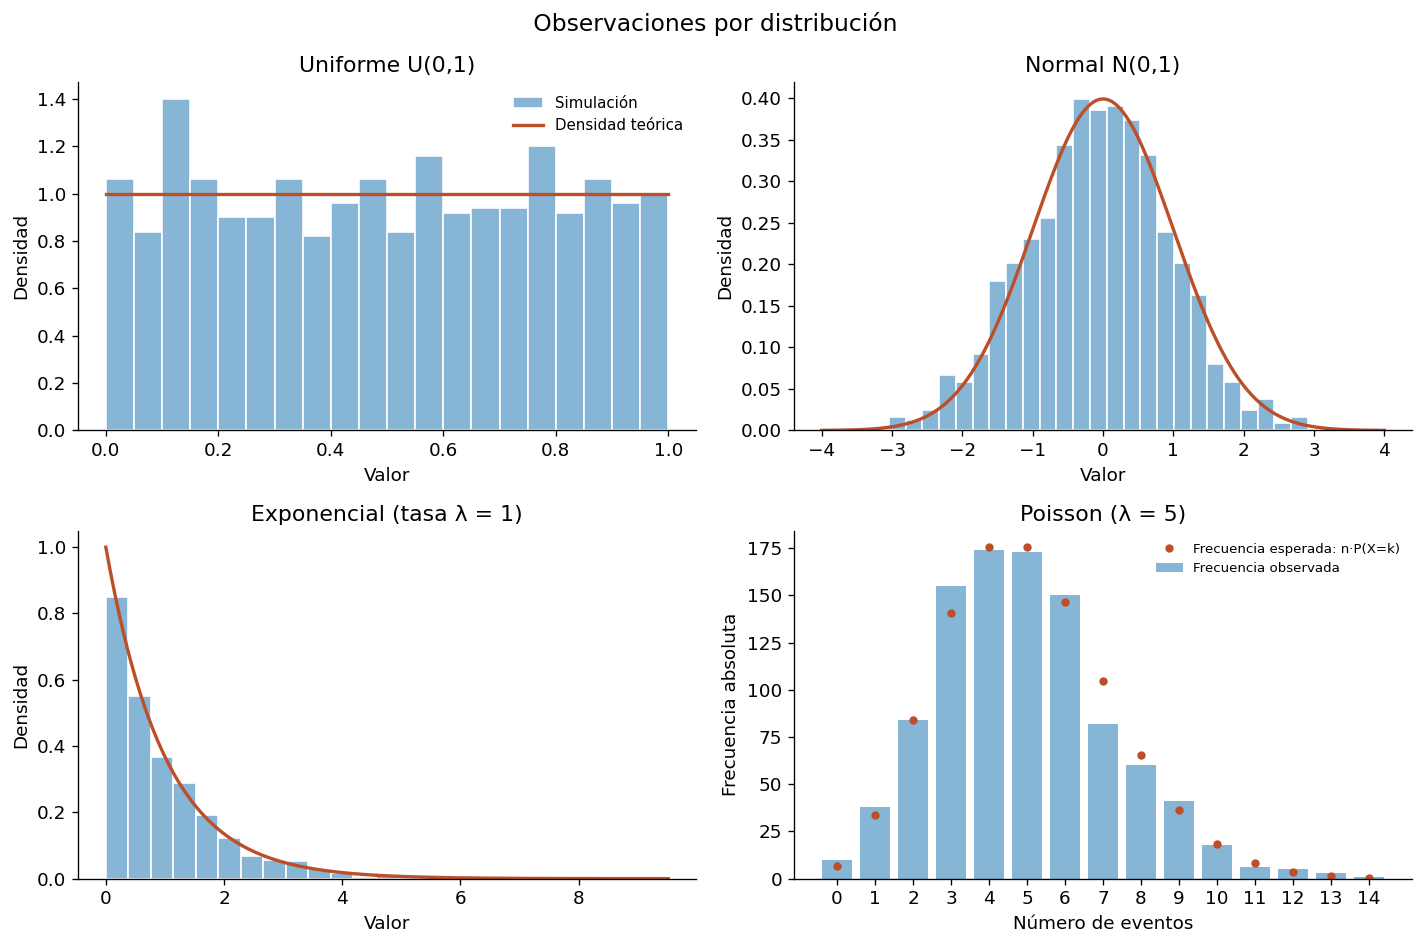

In [22]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
azul, naranja = "#86B5D5", "#BC4E28"

# Uniforme
ax = axs[0, 0]
ax.hist(uniforme, bins=np.linspace(0, 1, 21), density=True, color=azul, edgecolor="white", label="Simulación")
ax.plot([0, 1], [1, 1], color=naranja, linewidth=2, label="Densidad teórica")
ax.set(title="Uniforme U(0,1)", xlabel="Valor", ylabel="Densidad")
ax.legend(frameon=False, fontsize=9)

# Normal estándar.
ax = axs[0, 1]
ax.hist(normal, bins=25, density=True, color=azul, edgecolor="white")
x = np.linspace(min(normal.min(), -4), max(normal.max(), 4), 400)
ax.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color=naranja, linewidth=2)
ax.set(title="Normal N(0,1)", xlabel="Valor", ylabel="Densidad")

# Exponencial
ax = axs[1, 0]
ax.hist(exponencial, bins=25, density=True, color=azul, edgecolor="white")
x = np.linspace(0, exponencial.max(), 400)
ax.plot(x, lambda_exp * np.exp(-lambda_exp * x), color=naranja, linewidth=2)
ax.set(title="Exponencial (tasa λ = 1)", xlabel="Valor", ylabel="Densidad")

# Poisson
ax = axs[1, 1]
k = np.arange(int(poisson.max()) + 1)
frecuencias = np.bincount(poisson, minlength=len(k))
probabilidades = np.array([math.exp(-5) * 5**int(j) / math.factorial(int(j)) for j in k])
ax.bar(k, frecuencias, color=azul, width=0.8, label="Frecuencia observada")
ax.plot(k, n * probabilidades, "o", color=naranja, markersize=4, label="Frecuencia esperada: n·P(X=k)")
ax.set(title="Poisson (λ = 5)", xlabel="Número de eventos", ylabel="Frecuencia absoluta")
ax.set_xticks(k)
ax.legend(frameon=False, fontsize=8)
fig.suptitle(" Observaciones por distribución", fontsize=14)
fig.tight_layout()
plt.show()

La distribución uniforme presenta una densidad aproximadamente constante entre cero y uno, algunas diferencias entre las alturas de las barras corresponden a fluctuaciones de la muestra y el numero de observaciones.

La normal estándar muestra una forma aproximadamente simétrica, con una concentración cerca de cero.

La exponencial concentra observaciones pequeñas y presenta una cola cargada  hacia la derecha.

La Poisson toma únicamente valores enteros no negativos y se concentra alrededor de cinco.

Las medias y varianzas simuladas se comparan con sus referencias teóricas en la tabla, donde se observan diferencias propias de una muestra. Estas diferencias no implican por sí solas que el generador no sea correcto para ello aumentar el tamaño muestral tiende a mejorar la aproximación, aunque el error no necesariamente disminuye en cada ampliación. Las gráficas utilizadas y las tablas estadisticas observadas ofrecen una evaluación descriptiva complementaria para el ejercicio realizado.

# Conclusión:
El modelo determinístico describe una evolución fija, mientras que el estocástico nos permite
representar fluctuaciones bajo los mismos parámetros iniciales. Además la simulación de las cuatro
distribuciones muestra cómo sus parámetros determinan formas y estadísticos
diferentes.
Seguidamente comparar resultados numéricos y gráficos con referencias teóricas nos permite evaluar
su aproximacion a las distribuciónes.